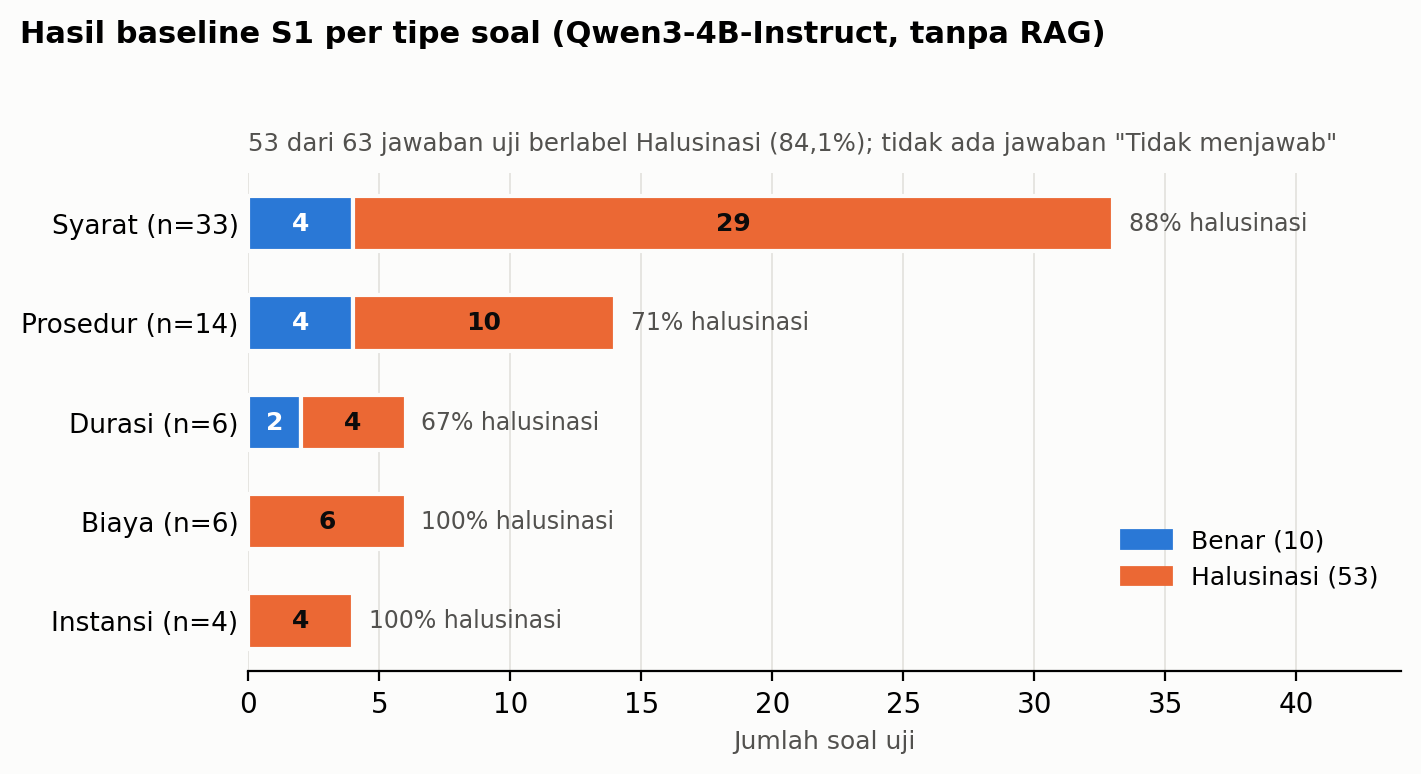

In [4]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

ct = pd.crosstab(d.tipe, d.label).reindex(urut).fillna(0).astype(int)
tot = ct.sum(axis=1)
BIRU, ORANYE, INK, INK2, BG = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#fcfcfb"

fig, ax = plt.subplots(figsize=(7.2, 3.9), dpi=200, facecolor=BG)
ax.set_facecolor(BG)

for yi, t in zip(range(len(urut))[::-1], urut):
    b, h = ct.loc[t, "Benar"], ct.loc[t, "Halusinasi"]
    if b:
        ax.barh(yi, b, color=BIRU, height=0.56, edgecolor=BG, linewidth=1.5)
        ax.text(b/2, yi, str(b), ha="center", va="center", color="white", fontsize=9, fontweight="bold")
    if h:
        ax.barh(yi, h, left=b, color=ORANYE, height=0.56, edgecolor=BG, linewidth=1.5)
        ax.text(b+h/2, yi, str(h), ha="center", va="center", color=INK, fontsize=9, fontweight="bold")
    ax.text(tot[t]+0.6, yi, f"{round(100*h/tot[t])}% halusinasi", va="center", color=INK2, fontsize=8.5)

ax.set_yticks(list(range(len(urut)))[::-1])
ax.set_yticklabels([f"{t} (n={tot[t]})" for t in urut], fontsize=9.5)
ax.set_xlim(0, tot.max() + 11)
ax.set_xlabel("Jumlah soal uji", color=INK2, fontsize=9)
for s in ["top", "right", "left"]:
    ax.spines[s].set_visible(False)
ax.xaxis.grid(True, color="#e6e5e1", linewidth=0.7)
ax.set_axisbelow(True)
ax.tick_params(axis="y", length=0)
ax.legend(handles=[Patch(color=BIRU, label="Benar (10)"), Patch(color=ORANYE, label="Halusinasi (53)")],
          loc="lower right", bbox_to_anchor=(1.0, 0.12), frameon=False, fontsize=9)
fig.suptitle("Hasil baseline S1 per tipe soal (Qwen3-4B-Instruct, tanpa RAG)", x=0.02, ha="left", fontsize=11, fontweight="bold")
ax.set_title('53 dari 63 jawaban uji berlabel Halusinasi (84,1%); tidak ada jawaban "Tidak menjawab"',
             loc="left", fontsize=8.8, color=INK2, pad=8)
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig("gambar1_distribusi_label_per_tipe.png", facecolor=BG)
plt.show()

In [5]:
import pandas as pd
from math import sqrt

URL = "https://raw.githubusercontent.com/Tonggi-Simanjuntak/llm-hallucination/main/data/processed/label_s1.csv"
d = pd.read_csv(URL)
assert len(d) == 63, len(d)

def wilson(k, n, z=1.96):
    p = k / n
    c = (p + z*z/(2*n)) / (1 + z*z/n)
    h = z * sqrt(p*(1-p)/n + z*z/(4*n*n)) / (1 + z*z/n)
    return max(0, (c-h)*100), (c+h)*100

n = len(d)
baris = []
for lab in ["Halusinasi", "Benar", "Tidak menjawab"]:
    k = int((d.label == lab).sum()); lo, hi = wilson(k, n)
    baris.append((lab, k, n, round(100*k/n, 1), round(lo, 1), round(hi, 1)))
for nama, mask in [
    ("Benar tanpa klaim tambahan (aturan ketat)", (d.label == "Benar") & (d.klaim_tambahan_tidak_didukung == "tidak")),
    ("Benar dengan klaim tambahan tak terverifikasi", (d.label == "Benar") & (d.klaim_tambahan_tidak_didukung == "ya")),
]:
    k = int(mask.sum()); lo, hi = wilson(k, n)
    baris.append((nama, k, n, round(100*k/n, 1), round(lo, 1), round(hi, 1)))
t4 = pd.DataFrame(baris, columns=["metrik", "jumlah", "dari", "persen", "ci95_bawah", "ci95_atas"])
display(t4)

urut = ["Syarat", "Prosedur", "Durasi", "Biaya", "Instansi"]
t5 = pd.crosstab(d.tipe, d.label).reindex(urut).fillna(0).astype(int)
for c in ["Benar", "Halusinasi", "Tidak menjawab"]:
    if c not in t5: t5[c] = 0
t5 = t5[["Benar", "Halusinasi", "Tidak menjawab"]]
t5["Total"] = t5.sum(axis=1)
t5["Halusinasi (%)"] = (100*t5.Halusinasi/t5.Total).round(1)
t5.loc["Semua tipe"] = [t5.Benar.sum(), t5.Halusinasi.sum(), t5["Tidak menjawab"].sum(), t5.Total.sum(), round(100*t5.Halusinasi.sum()/t5.Total.sum(), 1)]
display(t5)

t4.to_csv("tabel4_metrik_s1.csv", index=False)
kolom_int = ["Benar", "Halusinasi", "Tidak menjawab", "Total"]
t5[kolom_int] = t5[kolom_int].astype(int)
display(t5)
t5.to_csv("tabel5_distribusi_per_tipe.csv")

,metrik,jumlah,dari,persen,ci95_bawah,ci95_atas
0,Halusinasi,53,63,84.1,73.2,91.1
1,Benar,10,63,15.9,8.9,26.8
2,Tidak menjawab,0,63,0.0,0.0,5.7
3,Benar tanpa klaim tambahan (aturan ketat),3,63,4.8,1.6,13.1
4,Benar dengan klaim tambahan tak terverifikasi,7,63,11.1,5.5,21.2


label,Benar,Halusinasi,Tidak menjawab,Total,Halusinasi (%)
tipe,,,,,
Syarat,4.0,29.0,0.0,33.0,87.9
Prosedur,4.0,10.0,0.0,14.0,71.4
Durasi,2.0,4.0,0.0,6.0,66.7
Biaya,0.0,6.0,0.0,6.0,100.0
Instansi,0.0,4.0,0.0,4.0,100.0
Semua tipe,10.0,53.0,0.0,63.0,84.1


label,Benar,Halusinasi,Tidak menjawab,Total,Halusinasi (%)
tipe,,,,,
Syarat,4,29,0,33,87.9
Prosedur,4,10,0,14,71.4
Durasi,2,4,0,6,66.7
Biaya,0,6,0,6,100.0
Instansi,0,4,0,4,100.0
Semua tipe,10,53,0,63,84.1
